In [224]:
from google.colab import drive
drive.mount('/content/drive')

import sys, os
from pathlib import Path
try:
  import google.colab
  USING_COLAB = True
except:
  USING_COLAB = False

if USING_COLAB:

  os.chdir("/content")
  os.system("git clone https://github.com/src47/multibax-sklearn.git")
  os.chdir("multibax-sklearn")
  sys.path.extend(["/content/multibax-sklearn"])
  ! pip install python-ternary
else:
  os.chdir("../../") # cell can only be run once!

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Load data (Note this is some fake simulated data based on Makenna's 4 datapoints). I basically just fit a quadractic to both curves and used it to generate some points.


In [225]:
datapath = "/content/drive/Shared drives/BAX_catalyst/data/sample_catalyst.csv"


In [226]:
%load_ext autoreload
%autoreload 2

import warnings
import os

import numpy as np
from matplotlib import pyplot as plt
from tqdm import tqdm
from sklearn.gaussian_process.kernels import WhiteKernel, ConstantKernel, Matern, RBF
from sklearn.preprocessing import MinMaxScaler
import ipywidgets as widgets
from IPython.display import display


from src.utils import XY_from_csv, random_sampling_no_replace, load_ternary_data
from src.acquisition import run_acquisition
from src.algorithms import MultibandUnion, ConditionalMultiband, MultibandIntersection, ParetoPlusMultiband, ParetoFront, Wishlist, PercentileSet1D
from src.models import MGPR, fit_matern_hypers
from src.metrics import get_n_obtained, get_jaccard_posterior
from src.plotting import plot_final_metrics, plot_iteration_results, plot_algo_true_function

plt.style.use("src/matplotlib.rc")
warnings.filterwarnings('ignore')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [227]:
import numpy as np
add_noise = False
# X, Y = XY_from_csv(datapath, columns_x=['Time', 'Time'], columns_y=['Yield', 'Selectivity'])
X, Y = XY_from_csv(datapath, columns_x=['Time', 'Time'], columns_y=['Yield'])
X = np.expand_dims(X[:,0], axis = -1) # bug in the code above which requires me to load in time twice and then only pick one column
Y_noise_less = Y.copy()
if add_noise:
  sigma = 5
  noise = sigma * np.random.randn(Y.shape[0], Y.shape[1])
  Y = Y + noise

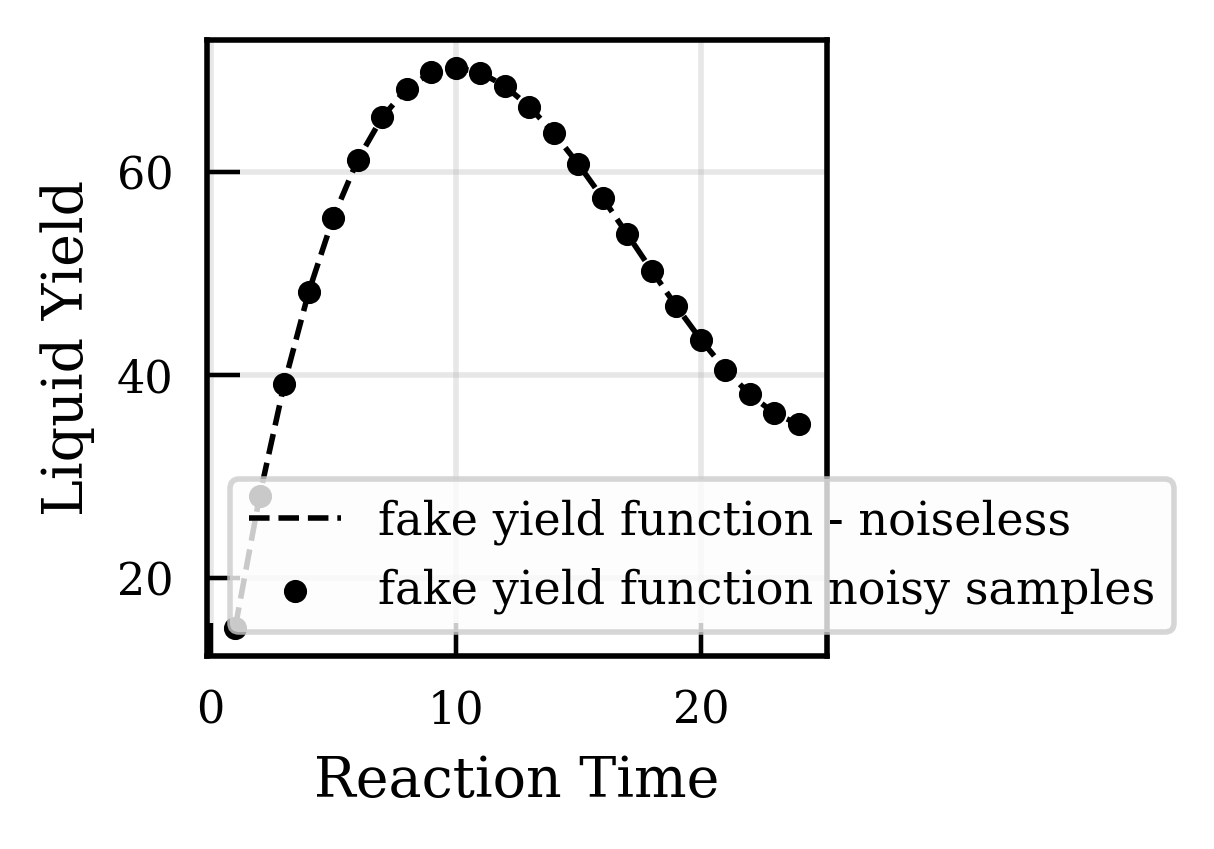

In [228]:
plt.figure(figsize=(2, 2))
plt.plot(X, Y_noise_less[:,0],"k--",label = 'fake yield function - noiseless')
plt.scatter(X, Y[:,0], c = 'k', label = 'fake yield function noisy samples', s = 10)
plt.xlabel('Reaction Time')
plt.ylabel('Liquid Yield')
plt.legend()
plt.show()

In [229]:
# Technically we shouldn't be able to normalize since we have collected any data; will fix this up
# Fixed this

x_scaler = MinMaxScaler(feature_range=(0, 1))
y_scaler = MinMaxScaler(feature_range=(-1, 1))

scalers = [x_scaler, y_scaler]

X_norm = x_scaler.fit_transform(X)

# Normalization based on parameters
yield_min = 0
yield_max = 100

y_scaler.fit(np.array([[yield_min],[yield_max]]))
Y_norm = y_scaler.transform(Y)

In [230]:
from src.algorithms import SubsetAlgorithm

class LevelBandAlgorithm(SubsetAlgorithm):
    def __init__(self, user_algo_params):
        super().__init__(user_algo_params)

    def user_algorithm(self, f_x, x):
        a = self.user_algo_params["a"]
        b = self.user_algo_params["b"]

        f_1 = f_x # only take the first property column
        ids1 = [np.argmax(f_1)]
        #ids1 = set(np.where(f_1 >= a)[0]) # the set of ids where f_1 is bigger/equal to a
        #ids2 = set(np.where(f_1 <= b)[0]) # the set of ids where f_2 is bigger/equal to b
        #ids_both = ids1.intersection(ids2) # the set of ids that match both conditions. i.e. a <= f_1 <= b

        return list(set(ids1))




In [231]:
# algorithm=LevelBandAlgorithm(user_algo_params = {"scalers": scalers, "a": 50.0, "b": 0.03})
algorithm=LevelBandAlgorithm(user_algo_params = {"scalers": scalers, "a": 40.0, "b": 55})


In [232]:
all_ids = list(np.arange(0, len(X_norm)))  # integer mapping design space
true_target_ids = algorithm.identify_subspace(f_x=Y_norm, x=X_norm)


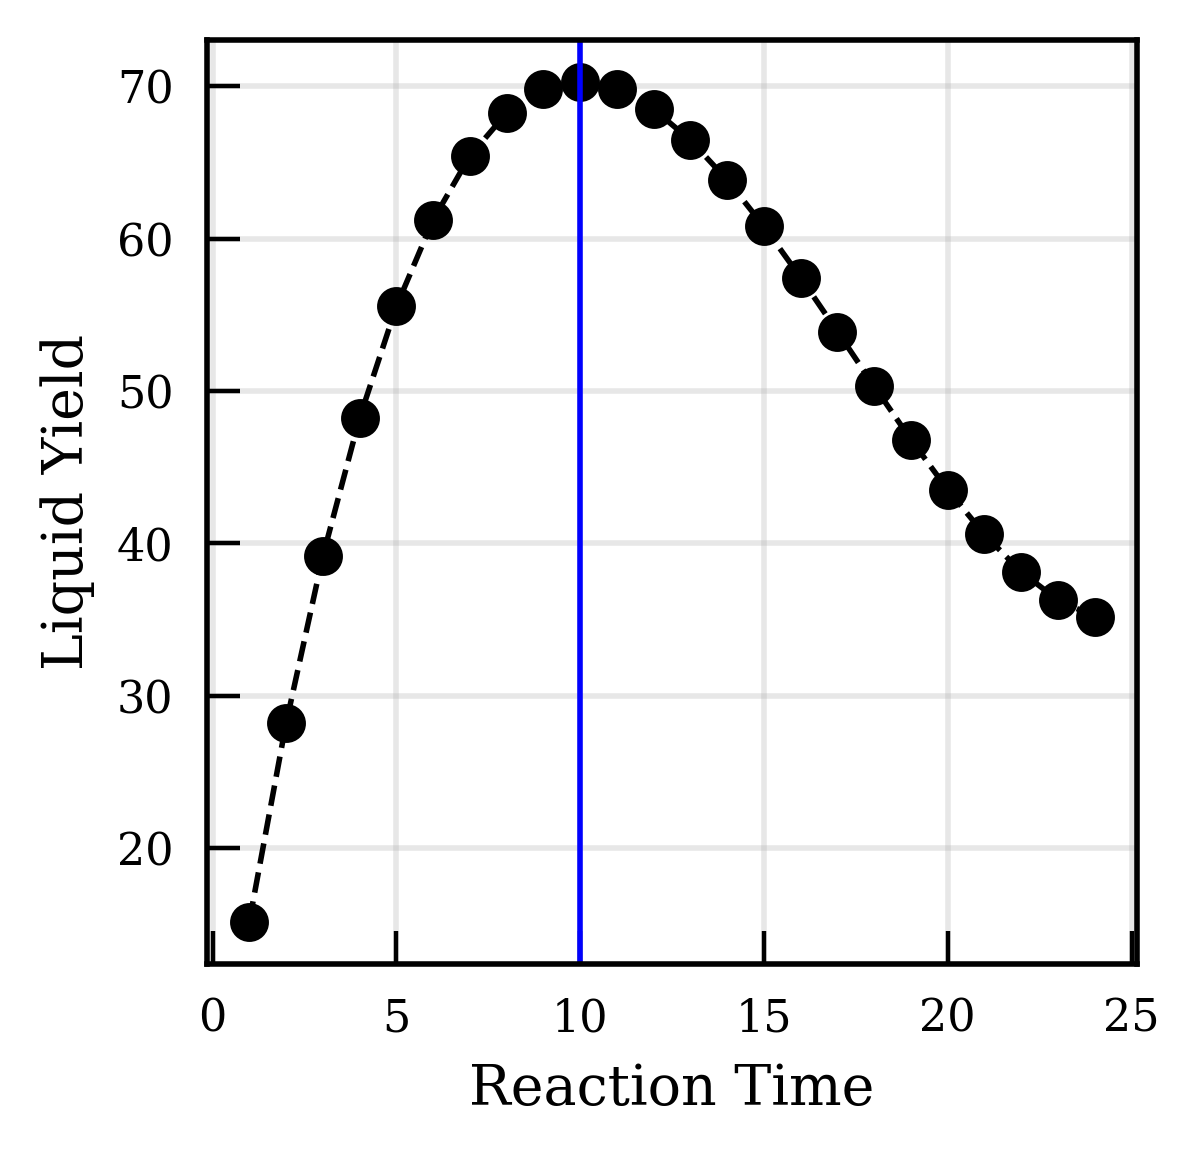

In [233]:
plt.figure(figsize=(3, 3))
plt.scatter(X, Y[:,0], label = 'fake yield function', color='k')
plt.plot(X, Y_noise_less[:,0], 'k--')
plt.xlabel('Reaction Time')
plt.ylabel('Liquid Yield')

for i in true_target_ids:
  plt.axvline(x = X[i], color = 'b')

plt.show()

In [234]:
n_features = 1
n_properties = 1

# kernel_initial = ConstantKernel(constant_value=1.0, constant_value_bounds="fixed") * Matern(nu = 5/2, length_scale= n_features * [0.5], length_scale_bounds= 'fixed') + WhiteKernel(noise_level=0.01, noise_level_bounds='fixed')
kernel_initial = ConstantKernel(constant_value=1.0, constant_value_bounds="fixed") * Matern(nu = 5/2, length_scale= n_features * [0.2], length_scale_bounds= 'fixed') + WhiteKernel(noise_level=0.005, noise_level_bounds='fixed') #switched to this after iteration 19 collected
kernel_initial_list = n_properties * [kernel_initial]


In [235]:
plotting = True
prevent_requery = True # (default this somewhere else)
n_posterior_samples = 30 # relevant for I|nfoBAX and mixedBAX ~ generally 10-15 is a good number; the more the merrier probably
fixed_hypers = True # true uses pre-fixed hypers fit to the entire dataset

In [236]:
strategy = "SwitchBAX"

if fixed_hypers:
  kernel_list = fit_matern_hypers(x_train=X_norm, y_train=Y_norm, kernel_list=kernel_initial_list, n_restarts_optimizer=1)


In [237]:
kernel_list

[1**2 * Matern(length_scale=0.2, nu=2.5) + WhiteKernel(noise_level=0.005)]

In [307]:
train_indices = [23, 0, 13, 8, 9, 18, 6]
#0, 9, 10, 20, 15, 6, 8
collected_ids = train_indices

x_train = X_norm[train_indices]
# y_train = Y_norm[train_indices]

# y_train = Y_norm[train_indices]

y_train = y_scaler.transform(np.expand_dims([35, 2.5, 63, 73, 70, 46, 68],axis=-1))
#2.5, 70.3, 68, 40, 54, 65, 72

In [308]:
Y[6]

array([65.4276])

In [309]:
#model.models

True


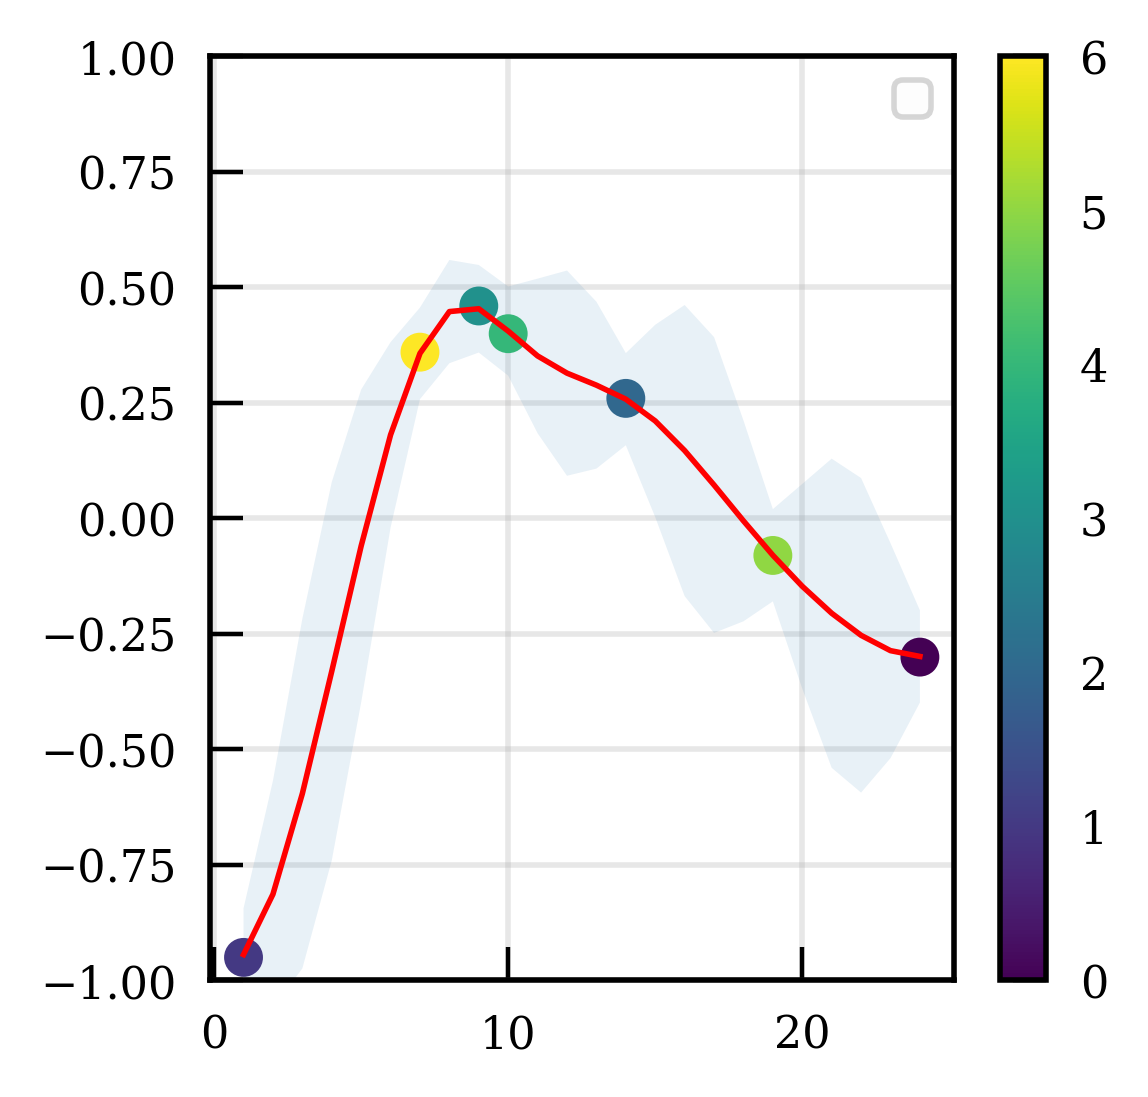

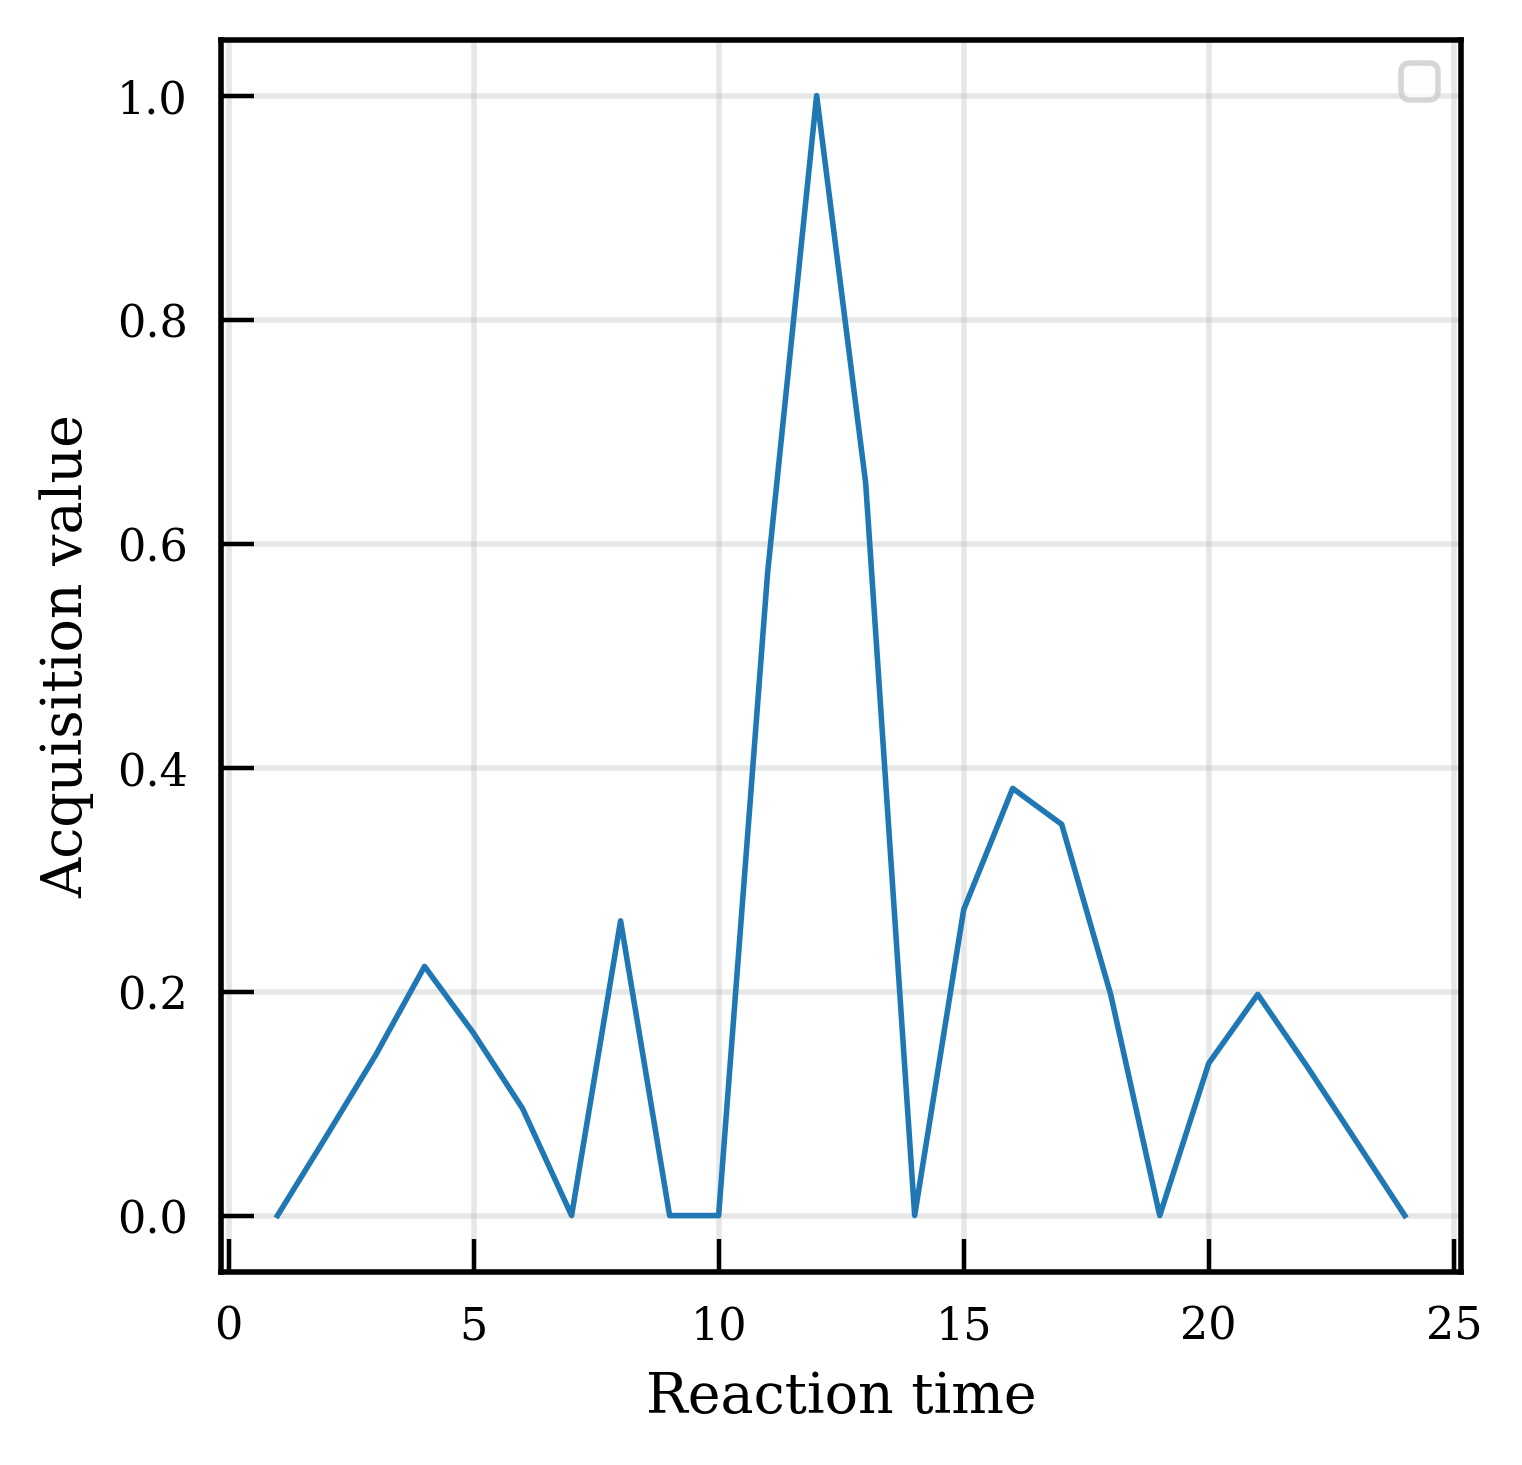

Index: 11
X to measure: [12]


In [310]:
multi_gpr = MGPR(kernel_list=kernel_list)
# Acquire next index
x_train_1, y_train_1, model, _, acquisition_function, switch_strategy = run_acquisition(x_train, y_train, X_norm, Y_norm, 'SwitchBAX', algorithm, multi_gpr, collected_ids, n_posterior_samples)

print(switch_strategy)

# Calculate metrics
posterior_mean, posterior_std = model.predict(X_norm)
predicted_target_ids = algorithm.identify_subspace(f_x = posterior_mean, x=X_norm)

# if (len(predicted_target_ids)/len(X_norm) > 0.5) and (switch_strategy == False):
#   x_train, y_train, model, _, acquisition_function, _ = run_acquisition(x_train, y_train, X_norm, Y_norm, 'InfoBAX', algorithm, multi_gpr, collected_ids, n_posterior_samples)
#   posterior_mean, posterior_std = model.predict(X_norm)
#   predicted_target_ids = algorithm.identify_subspace(f_x = posterior_mean, x=X_norm)
# else:
#   x_train = x_train_1
#   y_train = y_train_1

plt.figure(figsize=(3,3))
plt.plot(X, posterior_mean[:,0], color = 'red')
plt.fill_between(X[:,0], posterior_mean[:,0] - posterior_std[:,0], y2=posterior_mean[:,0] + posterior_std[:,0], alpha = 0.1)
plt.scatter(x_scaler.inverse_transform(x_train), y_train[:,0], c = np.arange(len(y_train)))
plt.colorbar()

# for i in true_target_ids:
#   plt.axvline(x = X_norm[i], color = 'blue')
plt.ylim(-1, 1)
#plt.fill_between(x=np.squeeze(X), y1=0.11250818, y2=-0.21568159, color='yellow',  interpolate=True, alpha=.3, label = 'desired region')
plt.legend()
plt.show()

# plot acquisition function
plt.plot(X, np.clip(acquisition_function/np.max(acquisition_function), 0, np.inf))
plt.xlabel('Reaction time')
plt.ylabel('Acquisition value')
plt.legend()
plt.show()

# Which ID to choose next!

next_id = np.argmax(acquisition_function)
print("Index:", next_id)
print("X to measure:", X[next_id])


In [311]:
train_indices

[23, 0, 13, 8, 9, 18, 6, 11]

Code for checking how good the GP posterior samples are:

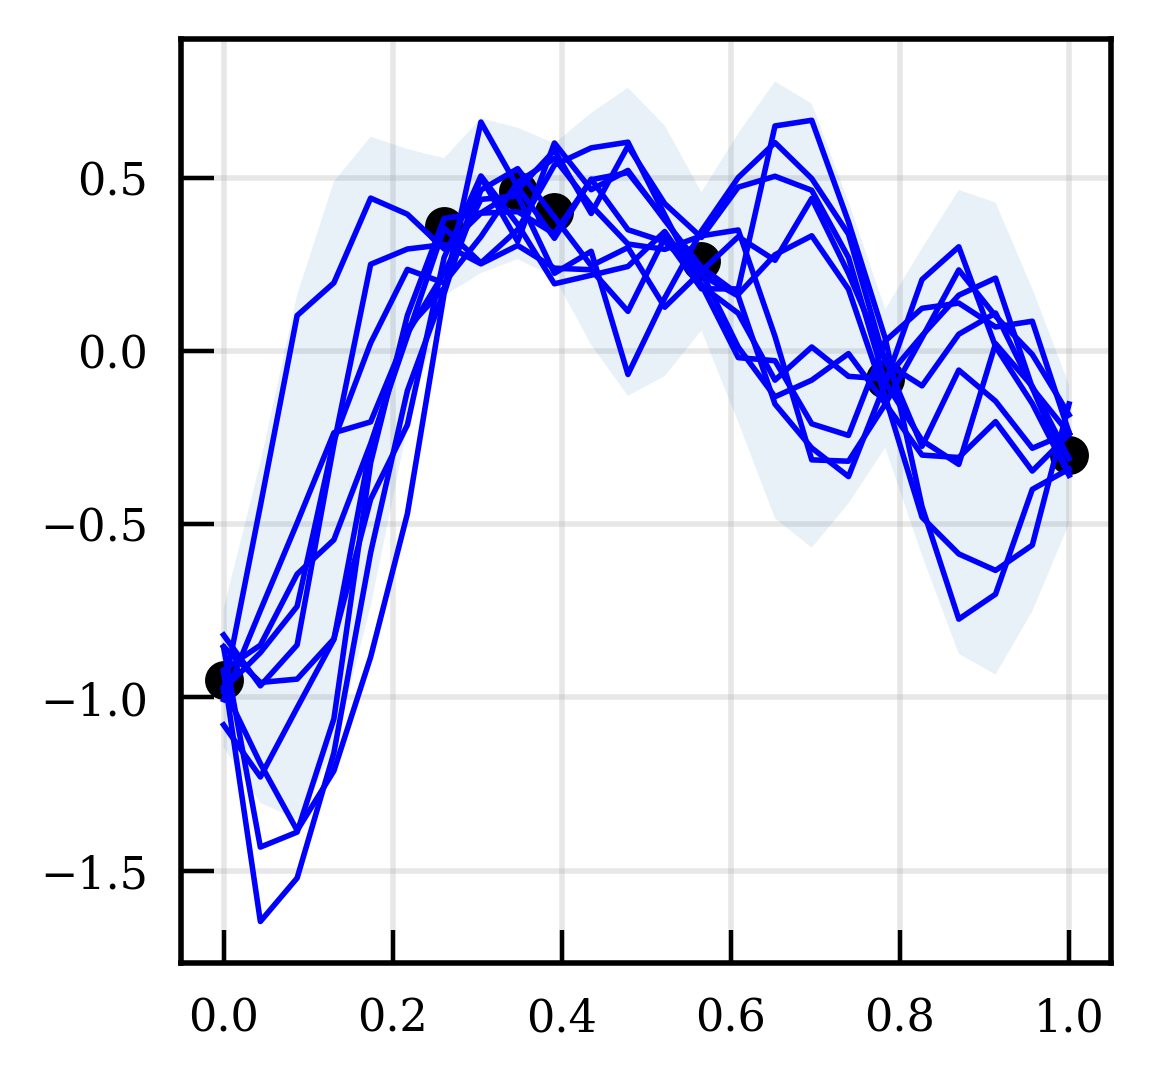

In [312]:
posterior_samples = model.sample_y(X_norm, n_samples=10)
#   predicted_target_ids = algorithm.identify_subspace(f_x = posterior_mean, x=X_norm)
# else:
#   x_train = x_train_1
#   y_train = y_train_1

plt.figure(figsize=(3,3))
for i in range(posterior_samples.shape[2]):
  plt.plot(X_norm, posterior_samples[:,0,i], color = 'blue')
plt.fill_between(X_norm[:,0], posterior_mean[:,0] - 2 * posterior_std[:,0], y2=posterior_mean[:,0] + 2 * posterior_std[:,0], alpha = 0.1)
plt.scatter(x_train, y_train[:,0], color = 'k')
plt.show()

# for i in true_target_ids:
#   plt.axvline(x = X_norm[i], color = 'blue')
# plt.show()

# # plot acquisition function
# plt.plot(X, np.clip(acquisition_function/np.max(acquisition_function), 0, np.inf))
# plt.xlabel('Reaction time')
# plt.ylabel('Acquisition value')
# plt.legend()
# plt.show()

# # Which ID to choose next!

# next_id = np.argmax(acquisition_function)
# print("Index:", next_id)
# print("X to measure:", X[next_id])

In [313]:
len(posterior_samples)

24

In [314]:
i

9

In [315]:
posterior_samples[:,0,0]

array([-0.85564097, -1.43174257, -1.38847571, -1.0616045 , -0.32308141,
        0.10248569,  0.38197699,  0.39783063,  0.46444379,  0.57835761,
        0.39636347,  0.59079607,  0.42469731,  0.32714073,  0.47228952,
        0.50374449,  0.4631807 ,  0.26938556, -0.09063373, -0.25844308,
       -0.32749999,  0.02083329, -0.10247295, -0.31088981])